# 02 – Which cell populations form the early thymic niche?

**Question.** Which annotated populations should enter the CausalCCC analysis of the early niche, and what do they look
like in terms of donor, chemistry and quality?

From notebook 01: labels and metadata come from the fig1 h5ad `.obs`, counts from the raw-count h5ad (same cells), and
the early window is 7–11 PCW (the authors' "early" stage bin).

Plan agreed for the analysis: two CausalCCC runs, **stroma → early lymphoid** first, then **early lymphoid → stroma**;
donors and chemistries pooled, with donor/chemistry added later as variables.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path("../..")
ZEN = ROOT / "data/thymus"
OUT = ROOT / "results/thymus_case1/02_cell_populations"
FIG = ROOT / "results/figures/thymus_case1"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

annot = ad.read_h5ad(ZEN / "thymus_annotated_matrix_files/HTA08.v01.A05.Science_human_fig1.h5ad", backed="r")
raw = ad.read_h5ad(ZEN / "HTA07.A01.v02.entire_data_raw_count.h5ad", backed="r")

# Annotation and design columns from fig1; per-cell QC values (computed by the authors on raw counts) from the raw file
cells = annot.obs[["Anno_level_1", "Anno_level_5", "Anno_stage", "donor", "Age", "method", "sort", "Source"]].astype(str)
cells = cells.join(raw.obs[["n_counts", "n_genes", "mito"]])

early = cells[cells.Anno_stage.str.endswith("_early")].copy()
print("cells at 7-11 PCW:", len(early), "| donors:", sorted(early.donor.unique()), "| ages:", sorted(early.Age.unique()))

/tmp/ipykernel_252191/1665916408.py:17: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  annot = ad.read_h5ad(ZEN / "thymus_annotated_matrix_files/HTA08.v01.A05.Science_human_fig1.h5ad", backed="r")


cells at 7-11 PCW: 49880 | donors: ['C34', 'C40', 'C41', 'F22', 'F23', 'F64', 'F74'] | ages: ['10w', '11w', '7w', '8w', '9w']


/tmp/ipykernel_252191/1665916408.py:18: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  raw = ad.read_h5ad(ZEN / "HTA07.A01.v02.entire_data_raw_count.h5ad", backed="r")


## 1. A written rule for selecting populations

A population (`Anno_level_5`) is kept if all three conditions hold:

- **(a) Lineage.** It is stromal (`Anno_level_1` = `TEC` or `Mesen`, which includes endothelium) or an early lymphoid
  population (ETP, DN, ILC3, NK, γδT). Later T-cell stages (DP and beyond), B cells, myeloid cells, erythroid cells and
  megakaryocytes are outside the question.
- **(b) Named in the paper.** It is named specifically in the paper's text on early development or on the niche
  interactions (quotes below, from the PMC version). A generic mention ("fibroblasts", "most stromal cell states") is
  not enough on its own; those populations are listed as *borderline*.
- **(c) Enough cells.** At least 50 cells at 7–11 PCW, so that MIIC has something to learn from.

In [2]:
EARLY_LYMPHOID = ["ETP", "DN(early)", "DN(P)", "DN(Q)", "ILC3", "NK", "γδT"]

# Populations named specifically in the paper, with the supporting quote
NAMED = {
    "cTEC":      "cTECs were more abundant during early development (7 to 8 PCW)",
    "Fb_1":      "The Fb1 population mentioned above dominated early development",
    "Endo":      "cTECs and endothelial cells express both JAG2 and DLL4",
    "mTEC(II)":  "RANKL-RANK ... signaling is confined between ILC3 and mTEC(II)s",
    "ETP":       "NOTCH1 is the main receptor expressed in early thymic progenitors (ETPs)",
    "DN(early)": "Differentiating T cells were mostly found at DN stage in 7 PCW samples",
    "DN(P)":     "Differentiating T cells were mostly found at DN stage in 7 PCW samples",
    "DN(Q)":     "Differentiating T cells were mostly found at DN stage in 7 PCW samples",
    "NK":        "In the early fetal samples (7 to 8 PCW), the lymphoid compartment contained NK cells, γδ T cells, and ILC3s",
    "γδT":       "In the early fetal samples (7 to 8 PCW), the lymphoid compartment contained NK cells, γδ T cells, and ILC3s",
    "ILC3":      "In the early fetal samples (7 to 8 PCW), the lymphoid compartment contained NK cells, γδ T cells, and ILC3s",
}
MIN_CELLS = 50

pop = early.groupby(["Anno_level_1", "Anno_level_5"]).size().rename("n_cells").reset_index()
pop["lineage"] = np.select(
    [pop.Anno_level_1.isin(["TEC", "Mesen"]), pop.Anno_level_5.isin(EARLY_LYMPHOID)],
    ["stroma", "early lymphoid"], default="other")
pop["a_lineage"] = pop.lineage != "other"
pop["b_named"] = pop.Anno_level_5.isin(NAMED)
pop["c_enough"] = pop.n_cells >= MIN_CELLS
pop["decision"] = np.select(
    [pop.a_lineage & pop.b_named & pop.c_enough, pop.a_lineage & pop.c_enough],
    ["keep", "borderline"], default="drop")
pop["quote"] = pop.Anno_level_5.map(NAMED).fillna("")
pop = pop.sort_values(["decision", "lineage", "n_cells"], ascending=[False, True, False])
pop[pop.lineage != "other"]

,Anno_level_1,Anno_level_5,n_cells,lineage,a_lineage,b_named,c_enough,decision,quote
29,T,DN(P),5700,early lymphoid,True,True,True,keep,Differentiating T cells were mostly found at D...
30,T,DN(Q),5329,early lymphoid,True,True,True,keep,Differentiating T cells were mostly found at D...
7,Innate_T,γδT,1518,early lymphoid,True,True,True,keep,"In the early fetal samples (7 to 8 PCW), the l..."
9,Innate_lymphoid,NK,995,early lymphoid,True,True,True,keep,"In the early fetal samples (7 to 8 PCW), the l..."
8,Innate_lymphoid,ILC3,294,early lymphoid,True,True,True,keep,"In the early fetal samples (7 to 8 PCW), the l..."
31,T,DN(early),201,early lymphoid,True,True,True,keep,Differentiating T cells were mostly found at D...
4,HSC,ETP,127,early lymphoid,True,True,True,keep,NOTCH1 is the main receptor expressed in early...
42,TEC,cTEC,9030,stroma,True,True,True,keep,cTECs were more abundant during early developm...
12,Mesen,Fb_1,822,stroma,True,True,True,keep,The Fb1 population mentioned above dominated e...
44,TEC,mTEC(II),322,stroma,True,True,True,keep,RANKL-RANK ... signaling is confined between I...


In [3]:
# Populations outside the two lineages, for completeness
pop.loc[pop.lineage == "other", ["Anno_level_1", "Anno_level_5", "n_cells"]].sort_values("n_cells", ascending=False).T

,32,33,38,19,17,25,27,3,26,18,28,34,6,35,5,10,20,1,37,36,21,24,2,0,16,22,23
Anno_level_1,T,T,T,Myeloid,Myeloid,T,T,Ery,T,Myeloid,T,T,Innate_T,T,HSC,Mast,Myeloid,B,T,T,Myeloid,Myeloid,Endo,B,Mgk,Myeloid,Myeloid
Anno_level_5,DP(P),DP(Q),αβT(entry),Mac,DC1,CD4+T,CD8αα(I),Ery,CD8+T,DC2,CD8αα(II),T(agonist),NKT,Th17,NMP,Mast,Mono,B_pro/pre,Treg(diff),Treg,aDC1,pDC,Lymph,B_naive,Mgk,aDC2,aDC3
n_cells,11108,8634,946,585,400,369,360,304,298,267,207,131,101,92,89,57,51,42,30,21,20,19,18,15,10,10,10


**Result.**
- **Kept:** stroma = cTEC, Fb_1, mTEC(II), Endo; early lymphoid = ETP, DN(early), DN(P), DN(Q), ILC3, NK, γδT.
- **Borderline** (stromal, enough cells, but only covered by generic mentions): Fb_2, VSMC, Fb_cycling, TEC(neuro),
  Epi_GCM2. They stay out for now and can be added back if a claim needs them (for example, "FGF7:FGFR2 comes from fibroblasts").
- **Dropped:** mcTEC, mTEC(I), mTEC(III), mTEC(IV), TEC(myo) (fewer than 50 cells), and everything outside the lineages.
- Caveat on mTEC(II): the RANKL claim is not tied to a stage in the text. We keep it because it exists at 7–11 PCW
  (322 cells), but it is relevant mainly for the lymphoid → stroma run.

## 2. Where do the kept cells come from?

In [4]:
keep = pop.loc[pop.decision == "keep", ["Anno_level_5", "lineage"]]
sel = early[early.Anno_level_5.isin(keep.Anno_level_5)].copy()
sel["lineage"] = sel.Anno_level_5.map(keep.set_index("Anno_level_5").lineage)
order = ["cTEC", "mTEC(II)", "Fb_1", "Endo", "ETP", "DN(early)", "DN(P)", "DN(Q)", "ILC3", "NK", "γδT"]

donor_order = ["C40", "C41", "C34", "F22", "F74", "F23", "F64"]   # by age: 7, 8, 9, 9, 10, 11, 11 PCW
by_donor = pd.crosstab(sel.Anno_level_5, sel.donor).reindex(index=order, columns=donor_order)
by_donor["total"] = by_donor.sum(axis=1)
by_donor

donor,C40,C41,C34,F22,F74,F23,F64,total
Anno_level_5,,,,,,,,
cTEC,5402,3528,60,8,21,4,7,9030
mTEC(II),310,11,0,0,1,0,0,322
Fb_1,3,2,37,112,126,354,188,822
Endo,73,47,11,15,30,17,40,233
ETP,99,11,0,2,4,11,0,127
DN(early),86,23,9,2,19,31,31,201
DN(P),2799,1108,28,213,329,625,598,5700
DN(Q),1498,1430,8,345,632,778,638,5329
ILC3,214,11,2,14,29,18,6,294


In [5]:
# Chemistry and sorting per population
pd.concat({"chemistry": pd.crosstab(sel.Anno_level_5, sel.method), "sort": pd.crosstab(sel.Anno_level_5, sel["sort"])},
          axis=1).reindex(order)

chemistry       sort          
                  3GEX  5GEX  45N 45P   TOT
Anno_level_5                               
cTEC              8942    88    4   0  9026
mTEC(II)           321     1    0   0   322
Fb_1               471   351  331  23   468
Endo               152    81    8   9   216
ETP                123     4    8   3   116
DN(early)          142    59   30   1   170
DN(P)             4745   955  617   8  5075
DN(Q)             4051  1278  773   5  4551
ILC3               257    37    1  17   276
NK                 862   133    9  83   903
γδT               1387   131    5  41  1472

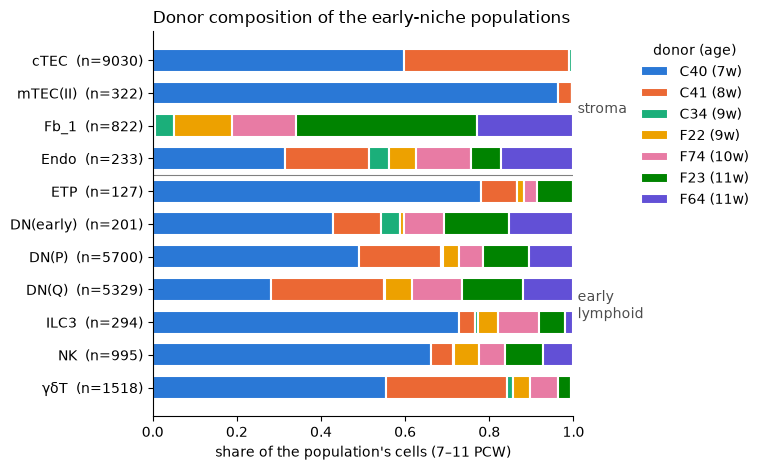

In [6]:
ages = early.groupby("donor").Age.first()
share = by_donor[donor_order].div(by_donor.total, axis=0)

# Categorical palette (fixed order, one colour per donor); white gaps separate the segments
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
fig, ax = plt.subplots(figsize=(8, 4.8))
left = np.zeros(len(order))
for d, c in zip(donor_order, colors):
    ax.barh(order, share[d], left=left, color=c, edgecolor="white", linewidth=1.5, height=0.7,
            label=f"{d} ({ages[d]})")
    left += share[d].values
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of the population's cells (7–11 PCW)")
ax.set_yticks(range(len(order)), [f"{p}  (n={by_donor.total[p]})" for p in order])
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.axhline(3.5, color="0.5", linewidth=0.8)
ax.text(1.01, 1.5, "stroma", transform=ax.get_yaxis_transform(), va="center", color="0.3")
ax.text(1.01, 7.5, "early\nlymphoid", transform=ax.get_yaxis_transform(), va="center", color="0.3")
ax.legend(title="donor (age)", bbox_to_anchor=(1.13, 1), loc="upper left", frameon=False)
ax.set_title("Donor composition of the early-niche populations", loc="left")
fig.tight_layout()
fig.savefig(FIG / "02_donor_composition.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading.**
- Stroma: cTEC and mTEC(II) come almost entirely from C40/C41 (7–8 PCW, 3′ chemistry, unsorted). Fb_1 comes almost
  entirely from the other five donors, and Endo is split between the two groups.
- Early lymphoid: every population is present in several donors, with C40/C41 the largest contributors.
- So, within the stroma, *cell type* and *donor* are strongly linked. This is the confounding we accepted when we
  decided to pool. Adding donor and chemistry as variables will make it visible in the network, but it cannot fully
  separate the two.

## 3. Quality per population and chemistry

These are the authors' per-cell values (computed on raw counts). Large differences between chemistries within a
population would be a technical effect for MIIC to absorb.

In [7]:
qc = sel.groupby(["Anno_level_5", "method"]).agg(
    cells=("n_genes", "size"), median_genes=("n_genes", "median"),
    median_counts=("n_counts", "median"), median_mito_pct=("mito", lambda x: 100 * x.median()))
qc.reindex(order, level=0).round(1)

cells  median_genes  median_counts  median_mito_pct
Anno_level_5 method                                                     
cTEC         3GEX     8942        3857.0        12267.5              2.3
             5GEX       88        2559.5         6099.5              2.8
mTEC(II)     3GEX      321        3257.0        10608.0              1.9
             5GEX        1         506.0         2055.0             67.5
Fb_1         3GEX      471        2510.0         8863.0              2.4
             5GEX      351        2470.0         6793.0              3.4
Endo         3GEX      152        3207.0        10431.5              2.3
             5GEX       81        2743.0         8034.0              4.3
ETP          3GEX      123        2308.0         7352.0              2.0
             5GEX        4        3230.5        12512.5              3.3
DN(early)    3GEX      142        4285.5        21370.0              2.4
             5GEX       59        4647.0        22560.0              3.7
DN(P)        3GEX     4745        3648.0        15367.0              2.3
             5GEX      955        3701.0        14254.0              3.2
DN(Q)        3GEX     4051        2268.0         7214.0              1.8
             5GEX     1278        2153.0         5947.0              2.4
ILC3         3GEX      257        2298.0         7431.0              1.7
             5GEX       37        2580.0         8267.0              4.6
NK           3GEX      862        1667.0         4751.5              2.1
             5GEX      133        2104.0         6616.0              3.7
γδT          3GEX     1387        3200.0        12557.0              2.2
             5GEX      131        3562.0        15007.0              3.4

**Reading.**
- The largest differences are between populations: DN(early) and DN(P) are the deepest (median ~15,000–22,000 counts),
  NK the shallowest (~5,000). This is expected biology (cell size and activity), not a problem.
- Within a population, 5′ cells have a higher mitochondrial fraction in every population (about 1–3 points higher).
  Detected genes are lower in 5′ for cTEC and Endo, higher for NK, and similar elsewhere. So chemistry has a modest
  but real technical effect, which supports adding `method` as a variable in the network.
- The 5′ subsets of cTEC (88 cells), mTEC(II) (1 cell) and ETP (4 cells) are tiny: within those populations, chemistry
  hardly varies, so MIIC cannot learn a chemistry effect there.

## 4. Proposed groups for run A (stroma → early lymphoid)

CausalCCC takes **one sender label and one receiver label** per run (`causalCCC.mosaic()` requires a single string).
Two ways to fit several populations into that:

1. **Merged groups.** Senders = all kept stromal cells, receivers = all kept early lymphoid cells. The population
   becomes a metadata variable, so MIIC can show *which* population a gene depends on. Problem: the merged groups
   are dominated by their largest member (below), unless we cap the number of cells per population.
2. **One run per sender–receiver pair** (for example, cTEC → ETP). Each network is easy to read, but this means many
   runs, and small populations (ETP, 127 cells) give little statistical power.

In [8]:
group_sizes = sel.groupby(["lineage", "Anno_level_5"]).size().rename("n").reset_index()
group_sizes["share_of_group"] = group_sizes.n / group_sizes.groupby("lineage").n.transform("sum")
group_sizes.set_index(["lineage", "Anno_level_5"]).loc[["stroma", "early lymphoid"]].round(2)

n  share_of_group
lineage        Anno_level_5                      
stroma         Endo           233            0.02
               Fb_1           822            0.08
               cTEC          9030            0.87
               mTEC(II)       322            0.03
early lymphoid DN(P)         5700            0.40
               DN(Q)         5329            0.38
               DN(early)      201            0.01
               ETP            127            0.01
               ILC3           294            0.02
               NK             995            0.07
               γδT           1518            0.11

In [9]:
# Cells selected for the next notebooks (one row per cell)
cols = ["Anno_level_5", "lineage", "donor", "Age", "method", "sort", "Source", "n_counts", "n_genes", "mito"]
sel[cols].rename(columns={"Anno_level_5": "population"}).to_csv(OUT / "selected_cells.csv")
pop.to_csv(OUT / "population_rule.csv", index=False)
print(len(sel), "cells written to", OUT / "selected_cells.csv")

24571 cells written to ../../results/thymus_case1/02_cell_populations/selected_cells.csv


## Summary

| | |
|---|---|
| Window | 7–11 PCW, 7 donors |
| Stroma (senders in run A) | cTEC 9,030 · Fb_1 822 · mTEC(II) 322 · Endo 233 |
| Early lymphoid (receivers in run A) | DN(P) 5,700 · DN(Q) 5,329 · γδT 1,518 · NK 995 · ILC3 294 · DN(early) 201 · ETP 127 |
| Borderline, not used yet | Fb_2, VSMC, Fb_cycling, TEC(neuro), Epi_GCM2 |
| Known limits | stromal cell type ≈ donor (cTEC/mTEC(II) from C40/C41, Fb_1 from others); chemistry differs in depth |

Decision needed before notebook 03: merged groups (with a per-population cell cap) or one run per sender–receiver pair.